In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("bestsellers with categories.csv")

In [3]:
df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [4]:
df.shape

(550, 7)

Датасет містить 550 записів про книги

In [5]:
df.columns = [
    "name", "author", "user_rating",
    "reviews", "price", "year", "genre"
]

In [6]:
df.isna().sum()

,0
name,0
author,0
user_rating,0
reviews,0
price,0
year,0
genre,0


Ні

In [7]:
df["genre"].unique()

array(['Non Fiction', 'Fiction'], dtype=object)

Fiction та Non Fiction

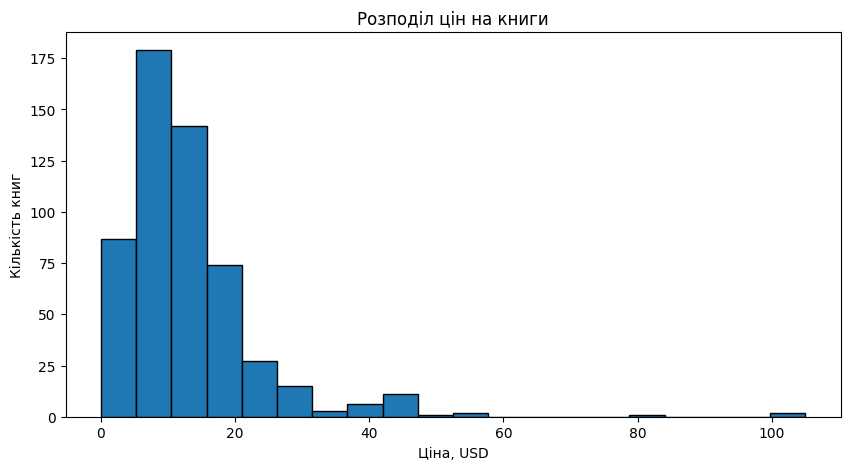

In [8]:
import matplotlib.pyplot as plt

df["price"].plot(
    kind="hist",
    bins=20,
    edgecolor="black",
    figsize=(10, 5)
)

plt.title("Розподіл цін на книги")
plt.xlabel("Ціна, USD")
plt.ylabel("Кількість книг")
plt.show()

In [9]:
print("Максимальна ціна:", df["price"].max())
print("Мінімальна ціна:", df["price"].min())
print("Середня ціна:", df["price"].mean())
print("Медіанна ціна:", df["price"].median())

Максимальна ціна: 105
Мінімальна ціна: 0
Середня ціна: 13.1
Медіанна ціна: 11.0


Максимальна ціна: 105
Мінімальна ціна: 0
Середня ціна: 13.1
Медіанна ціна: 11.0

In [11]:
df["user_rating"].max()

4.9

найвищий рейтинг - 4.9

In [12]:
df[df["user_rating"] == df["user_rating"].max()].shape[0]

52

52 книги мають той самий рейтинг

In [14]:
df.loc[df["reviews"].idxmax(), ["name", "reviews"]]

,534
name,Where the Crawdads Sing
reviews,87841


Where the Crawdads Sing - 87 841 відгук.

In [15]:
books_2015 = df[df["year"] == 2015]

books_2015.loc[books_2015["price"].idxmax(), ["name", "price"]]

,277
name,Publication Manual of the American Psychologic...
price,46


Publication Manual of the American Psychological Association, 6th Edition - 46 USD

In [16]:
df[(df["genre"] == "Fiction") & (df["year"] == 2010)].shape[0]

20

20 книг

In [17]:
df[
    (df["user_rating"] == 4.9) &
    ((df["year"] == 2010) | (df["year"] == 2011))
].shape[0]

1

1 книга

In [18]:
sorted_books = df[
    (df["year"] == 2015) & (df["price"] < 8)
].sort_values(by="price")

sorted_books

,name,author,user_rating,reviews,price,year,genre
507,To Kill a Mockingbird,Harper Lee,4.8,26234,0,2015,Fiction
54,Creative Haven Creative Cats Coloring Book (Ad...,Marjorie Sarnat,4.8,4022,4,2015,Non Fiction
206,Knock-Knock Jokes for Kids,Rob Elliott,4.5,3673,4,2015,Non Fiction
111,First 100 Words,Roger Priddy,4.7,17323,4,2015,Non Fiction
210,Laugh-Out-Loud Jokes for Kids,Rob Elliott,4.6,6990,4,2015,Non Fiction
123,Giraffes Can't Dance,Giles Andreae,4.8,14038,4,2015,Fiction
55,Creative Haven Owls Coloring Book (Adult Color...,Marjorie Sarnat,4.8,3871,5,2015,Non Fiction
63,Dear Zoo: A Lift-the-Flap Book,Rod Campbell,4.8,10922,5,2015,Fiction
224,Love You Forever,Robert Munsch,4.8,18613,5,2015,Fiction
478,The Very Hungry Caterpillar,Eric Carle,4.9,19546,5,2015,Fiction


In [19]:
sorted_books.iloc[-1][["name", "price"]]

,253
name,Old School (Diary of a Wimpy Kid #10)
price,7


Old School (Diary of a Wimpy Kid #10)

In [20]:
genre_prices = df.groupby("genre")["price"].agg(["max", "min"])
genre_prices

,max,min
genre,,
Fiction,82,0
Non Fiction,105,0


Максимальна ціна Fiction: 82 USD
Мінімальна ціна Fiction: 0 USD
Максимальна ціна Non Fiction: 105 USD
Мінімальна ціна Non Fiction: 0 USD

In [21]:
author_books = df.groupby("author")["name"].agg(["count"])
author_books

,count
author,
Abraham Verghese,2
Adam Gasiewski,1
Adam Mansbach,1
Adir Levy,1
Admiral William H. McRaven,1
...,...
Walter Isaacson,3
William Davis,2
William P. Young,2


248 rows × 1 columns - 248 авторів та один стовпець.

In [22]:
author_books.sort_values("count", ascending=False).head(1)

,count
author,
Jeff Kinney,12


Jeff Kinney має найбільше книг

12 книг

In [23]:
author_rating = df.groupby("author")["user_rating"].agg(["mean"])
author_rating

,mean
author,
Abraham Verghese,4.600000
Adam Gasiewski,4.400000
Adam Mansbach,4.800000
Adir Levy,4.800000
Admiral William H. McRaven,4.700000
...,...
Walter Isaacson,4.566667
William Davis,4.400000
William P. Young,4.600000


In [24]:
author_rating.sort_values("mean").head(1)

,mean
author,
Donna Tartt,3.9


Donna Tartt

3.9

In [25]:
authors = pd.concat([author_books, author_rating], axis=1)
authors

,count,mean
author,,
Abraham Verghese,2,4.600000
Adam Gasiewski,1,4.400000
Adam Mansbach,1,4.800000
Adir Levy,1,4.800000
Admiral William H. McRaven,1,4.700000
...,...,...
Walter Isaacson,3,4.566667
William Davis,2,4.400000
William P. Young,2,4.600000


In [26]:
authors_sorted = authors.sort_values(
    by=["count", "mean"],
    ascending=[True, True]
)

authors_sorted

,count,mean
author,,
Muriel Barbery,1,4.000000
Chris Cleave,1,4.100000
Ian K. Smith M.D.,1,4.100000
Pierre Dukan,1,4.100000
Elizabeth Strout,1,4.200000
...,...,...
American Psychological Association,10,4.500000
Suzanne Collins,11,4.663636
Gary Chapman,11,4.736364


In [27]:
authors_sorted.head(1)

,count,mean
author,,
Muriel Barbery,1,4.0


Muriel Barbery